# 07 - Volatility Regimes

High vol clusters with high vol. Detect the regime.


## Setup

In [1]:
# --- setup --------------------------------------------------------
import sys, json
sys.path.insert(0, r"D:\\Projects\\done\\eth_bot\\eth_bot_v2")
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)
plt.rcParams["figure.figsize"] = (13, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
np.random.seed(42)

SYMBOL = "ETHUSDT"
OUT = Path(r"D:\\Projects\\done\\eth_bot\\eth_bot_v2") / "reports" / "forecasts"
OUT.mkdir(parents=True, exist_ok=True)
DB = Path(r"D:\\Projects\\done\\eth_bot\\eth_bot_v2") / "database" / "market.db"

def sql(q, **p):
    with sqlite3.connect(DB) as c:
        return pd.read_sql_query(q, c, params=p)

from database.config.api.binance import get_klines

def fetch(symbol, interval, limit=500):
    raw = get_klines(symbol, interval=interval, limit=limit)
    df = pd.DataFrame(raw, columns=["open_time","open","high","low","close",
        "volume","close_time","quote_volume","trades","taker_base","taker_quote","ignore"])
    df["date"] = pd.to_datetime(df["open_time"], unit="ms", utc=True).dt.tz_convert(None)
    for c in ("open","high","low","close","volume"):
        df[c] = df[c].astype(float)
    return df[["date","open","high","low","close","volume"]].set_index("date").iloc[:-1]

def action_block(name, action, reason, price=None, entry=None, stop=None,
                 target=None, conf=None, extra=None):
    print("=" * 62)
    print(f"  {name}")
    print("=" * 62)
    print(f"  time   : {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M')} UTC")
    if price is not None: print(f"  price  : {price:,.2f}")
    if conf  is not None: print(f"  conf   : {conf:.2f}")
    print(f"  ACTION : {action}")
    print(f"  REASON : {reason}")
    if entry is not None:
        print(f"  entry  : {entry:,.2f}   stop: {stop:,.2f}   target: {target:,.2f}")
    if extra:
        for k, v in extra.items():
            print(f"  {k:<6} : {v}")
    print("=" * 62)
    return {"action": action, "reason": reason, "price": price,
            "entry": entry, "stop": stop, "target": target, "conf": conf}

## 1. Load

In [2]:
v = sql("SELECT open_time, close FROM ohlcv WHERE symbol='ETHUSDT' AND timeframe='1d' ORDER BY open_time")
v["date"] = pd.to_datetime(v.open_time, unit="ms")
v = v.set_index("date").drop(columns="open_time")
v["ret"] = v["close"].pct_change()
v["vol30"] = v["ret"].rolling(30).std() * np.sqrt(365)
print(v.tail(3))

              close       ret     vol30
date                                   
2026-09-30  2686.01  0.002999  0.440697
2026-10-01  2706.42  0.007599  0.433025
2026-10-02  2668.59 -0.013978  0.434438


## 2. Current vs historical

In [3]:
cur_vol = float(v["vol30"].iloc[-1])
pct = float((v["vol30"].dropna() < cur_vol).mean())
print(f"current 30d vol: {cur_vol*100:.2f}%")
print(f"percentile     : {pct*100:.1f}%")
if pct > 0.8: print("regime: HIGH vol")
elif pct < 0.2: print("regime: LOW vol")
else: print("regime: NORMAL vol")

current 30d vol: 43.44%
percentile     : 11.7%
regime: LOW vol


## 3. Chart

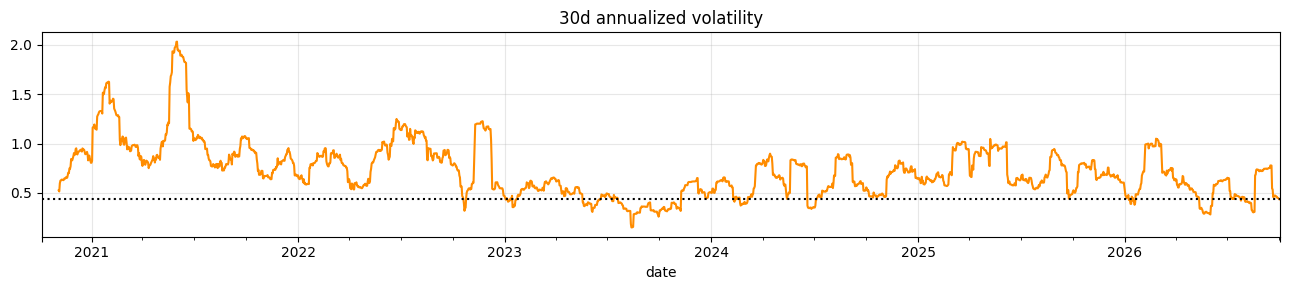

In [4]:
fig, ax = plt.subplots(figsize=(13, 3))
v["vol30"].plot(ax=ax, color="darkorange", title="30d annualized volatility")
ax.axhline(cur_vol, ls=":", color="black")
plt.tight_layout(); plt.show()

## 4. Action

In [5]:
if pct > 0.85:   action, reason = "FLAT", "high vol — reduce size"
elif pct < 0.15: action, reason = "LONG", "low vol — trend likely, buy breakouts"
else:            action, reason = "FLAT", "normal vol"
action_block("VOLATILITY REGIME", action, reason,
    price=float(v["close"].iloc[-1]), extra={"vol_pct": f"{pct*100:.1f}%"})

  VOLATILITY REGIME
  time   : 2026-10-04 10:43 UTC
  price  : 2,668.59
  ACTION : LONG
  REASON : low vol — trend likely, buy breakouts
  vol_pct : 11.7%


{'action': 'LONG',
 'reason': 'low vol — trend likely, buy breakouts',
 'price': 2668.59,
 'entry': None,
 'stop': None,
 'target': None,
 'conf': None}